In [2]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import cv2

from keras import layers, models, regularizers
from tensorflow.keras.applications import DenseNet169
from tensorflow.keras.applications.densenet import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from collections import Counter

In [3]:
SEED = 42
BATCH_SIZE = 32
IMG_SIZE = (224, 224)

TEST_SIZE = 0.20
VAL_SIZE_FROM_TRAIN = 0.15

EPOCHS = 30
LEARNING_RATE = 0.0001

USE_DULL_RAZOR = True
HAIR_THRESHOLD = 10
INPAINT_RADIUS = 6

IMAGES_DIR = "../data/images"
CSV_PATH = "../data/GroundTruth.csv"

CHECKPOINT_PATH = "../models/transfer_learning/best_densenet169_undersampling.keras"
FINAL_MODEL_PATH = "../models/transfer_learning/densenet169_undersampling_final.keras"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
metadata = pd.read_csv(CSV_PATH)

classes = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]

class_code = {label: code for code, label in enumerate(classes)}
class_name = {code: label for code, label in enumerate(classes)}

print(metadata.head())
print(class_code)
print(class_name)

          image  MEL   NV  BCC  AKIEC  BKL   DF  VASC
0  ISIC_0024306  0.0  1.0  0.0    0.0  0.0  0.0   0.0
1  ISIC_0024307  0.0  1.0  0.0    0.0  0.0  0.0   0.0
2  ISIC_0024308  0.0  1.0  0.0    0.0  0.0  0.0   0.0
3  ISIC_0024309  0.0  1.0  0.0    0.0  0.0  0.0   0.0
4  ISIC_0024310  1.0  0.0  0.0    0.0  0.0  0.0   0.0
{'MEL': 0, 'NV': 1, 'BCC': 2, 'AKIEC': 3, 'BKL': 4, 'DF': 5, 'VASC': 6}
{0: 'MEL', 1: 'NV', 2: 'BCC', 3: 'AKIEC', 4: 'BKL', 5: 'DF', 6: 'VASC'}


In [5]:
def find_file(directory, base_name, extensions):
    for extension in extensions:
        path = os.path.join(directory, base_name + extension)
        if os.path.exists(path):
            return path
    return None


def prepare_metadata_with_image_paths(images_dir, metadata, class_code):
    rows = []

    for _, row in metadata.iterrows():
        image_name = str(row["image"])
        image_path = find_file(images_dir, image_name, [".jpg", ".jpeg", ".png"])

        if image_path is None:
            continue

        class_label = row[classes].idxmax()
        coded_label = class_code[class_label]

        rows.append({
            "image": image_name,
            "image_path": image_path,
            "label": coded_label,
            "class_name": class_label
        })

    return pd.DataFrame(rows)


prepared_metadata = prepare_metadata_with_image_paths(
    IMAGES_DIR,
    metadata,
    class_code
)

print(prepared_metadata.head())
print("Quantidade de imagens encontradas:", len(prepared_metadata))
print(prepared_metadata["class_name"].value_counts())


          image                       image_path  label class_name
0  ISIC_0024306  ../data/images/ISIC_0024306.jpg      1         NV
1  ISIC_0024307  ../data/images/ISIC_0024307.jpg      1         NV
2  ISIC_0024308  ../data/images/ISIC_0024308.jpg      1         NV
3  ISIC_0024309  ../data/images/ISIC_0024309.jpg      1         NV
4  ISIC_0024310  ../data/images/ISIC_0024310.jpg      0        MEL
Quantidade de imagens encontradas: 10015
class_name
NV       6705
MEL      1113
BKL      1099
BCC       514
AKIEC     327
VASC      142
DF        115
Name: count, dtype: int64


In [6]:
train_df, test_df = train_test_split(
    prepared_metadata,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=prepared_metadata["label"]
)

print("Distribuição original do treino:")
print(train_df["class_name"].value_counts().sort_index())

print("\nDistribuição original do teste:")
print(test_df["class_name"].value_counts().sort_index())

min_class_count = train_df["label"].value_counts().min()

train_under_df = (
    train_df
    .groupby("label", group_keys=False)
    .apply(lambda x: x.sample(n=min_class_count, random_state=SEED))
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

print("\nMenor quantidade de amostras por classe no treino:", min_class_count)
print("\nDistribuição do treino após undersampling:")
print(train_under_df["class_name"].value_counts().sort_index())


Distribuição original do treino:
class_name
AKIEC     262
BCC       411
BKL       879
DF         92
MEL       890
NV       5364
VASC      114
Name: count, dtype: int64

Distribuição original do teste:
class_name
AKIEC      65
BCC       103
BKL       220
DF         23
MEL       223
NV       1341
VASC       28
Name: count, dtype: int64

Menor quantidade de amostras por classe no treino: 92

Distribuição do treino após undersampling:
class_name
AKIEC    92
BCC      92
BKL      92
DF       92
MEL      92
NV       92
VASC     92
Name: count, dtype: int64


In [8]:
print(train_under_df.columns)
print(train_under_df.head())

Index(['image', 'image_path', 'class_name'], dtype='str')
          image                       image_path class_name
0  ISIC_0029877  ../data/images/ISIC_0029877.jpg       VASC
1  ISIC_0033749  ../data/images/ISIC_0033749.jpg       VASC
2  ISIC_0024662  ../data/images/ISIC_0024662.jpg       VASC
3  ISIC_0025696  ../data/images/ISIC_0025696.jpg      AKIEC
4  ISIC_0032110  ../data/images/ISIC_0032110.jpg        MEL


In [9]:
train_under_df = train_under_df.copy()
test_df = test_df.copy()

train_under_df["label"] = train_under_df["class_name"].map(class_code)
test_df["label"] = test_df["class_name"].map(class_code)

print(train_under_df.head())
print(train_under_df["label"].value_counts().sort_index())

          image                       image_path class_name  label
0  ISIC_0029877  ../data/images/ISIC_0029877.jpg       VASC      6
1  ISIC_0033749  ../data/images/ISIC_0033749.jpg       VASC      6
2  ISIC_0024662  ../data/images/ISIC_0024662.jpg       VASC      6
3  ISIC_0025696  ../data/images/ISIC_0025696.jpg      AKIEC      3
4  ISIC_0032110  ../data/images/ISIC_0032110.jpg        MEL      0
label
0    92
1    92
2    92
3    92
4    92
5    92
6    92
Name: count, dtype: int64


In [10]:
train_fit_df, val_df = train_test_split(
    train_under_df,
    test_size=VAL_SIZE_FROM_TRAIN,
    random_state=SEED,
    stratify=train_under_df["label"]
)

print("Treino usado no fit:", len(train_fit_df))
print("Validação:", len(val_df))
print("Teste final:", len(test_df))

print("\nDistribuição treino final:")
print(train_fit_df["class_name"].value_counts().sort_index())

print("\nDistribuição validação:")
print(val_df["class_name"].value_counts().sort_index())

Treino usado no fit: 547
Validação: 97
Teste final: 2003

Distribuição treino final:
class_name
AKIEC    78
BCC      78
BKL      78
DF       78
MEL      79
NV       78
VASC     78
Name: count, dtype: int64

Distribuição validação:
class_name
AKIEC    14
BCC      14
BKL      14
DF       14
MEL      13
NV       14
VASC     14
Name: count, dtype: int64


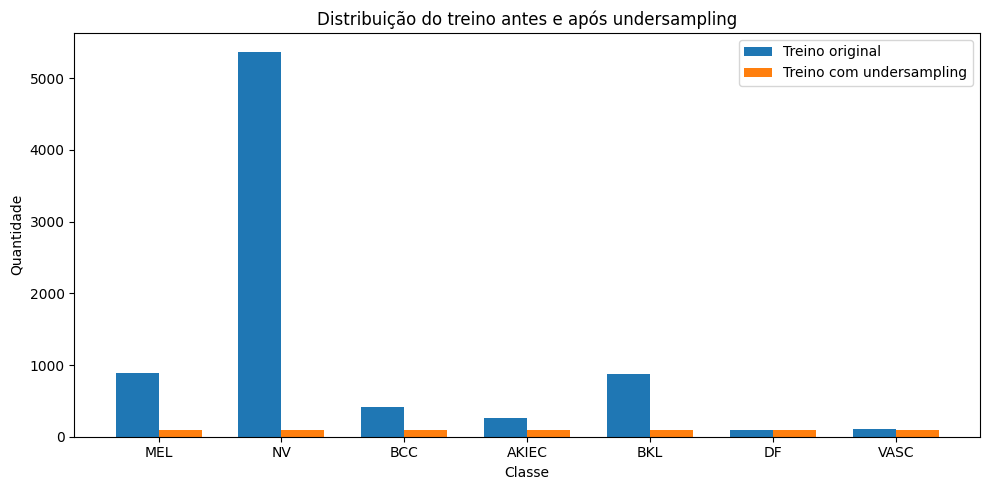

In [11]:
original_counts = train_df["class_name"].value_counts().reindex(classes)
under_counts = train_under_df["class_name"].value_counts().reindex(classes)

x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, original_counts.values, width, label="Treino original")
plt.bar(x + width/2, under_counts.values, width, label="Treino com undersampling")

plt.xticks(x, classes)
plt.ylabel("Quantidade")
plt.xlabel("Classe")
plt.title("Distribuição do treino antes e após undersampling")
plt.legend()
plt.tight_layout()
plt.savefig("distribuicao_undersampling.png", dpi=300, bbox_inches="tight")
plt.show()


In [12]:
def dull_razor_bgr(image_bgr, threshold=HAIR_THRESHOLD, inpaint_radius=INPAINT_RADIUS):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)

    blackhat_blur = cv2.GaussianBlur(blackhat, (3, 3), 0)

    _, mask = cv2.threshold(
        blackhat_blur,
        threshold,
        255,
        cv2.THRESH_BINARY
    )

    clean = cv2.inpaint(
        image_bgr,
        mask,
        inpaint_radius,
        cv2.INPAINT_TELEA
    )

    return clean, mask

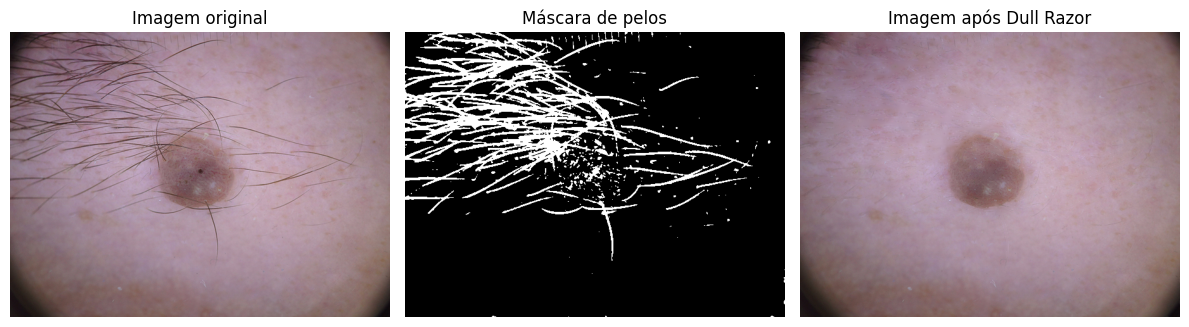

In [13]:
sample_row = train_df.sample(1, random_state=SEED).iloc[0]

image_bgr = cv2.imread(sample_row["image_path"], cv2.IMREAD_COLOR)

if image_bgr is None:
    raise ValueError(f"Não foi possível ler a imagem: {sample_row['image_path']}")

clean_bgr, hair_mask = dull_razor_bgr(image_bgr)

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
clean_rgb = cv2.cvtColor(clean_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_rgb)
plt.title("Imagem original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(hair_mask, cmap="gray")
plt.title("Máscara de pelos")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clean_rgb)
plt.title("Imagem após Dull Razor")
plt.axis("off")

plt.tight_layout()
plt.savefig("exemplo_dull_razor.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")


def load_image_with_optional_dull_razor(path):
    if isinstance(path, bytes):
        path = path.decode("utf-8")

    image_bgr = cv2.imread(path, cv2.IMREAD_COLOR)

    if image_bgr is None:
        raise ValueError(f"Não foi possível carregar a imagem: {path}")

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    if USE_DULL_RAZOR:
        image_rgb = dull_razor_remove_hair(image_rgb)

    image_rgb = cv2.resize(image_rgb, IMG_SIZE)

    return image_rgb.astype("float32")


def load_image_tf(path, label):
    image = tf.numpy_function(
        func=load_image_with_optional_dull_razor,
        inp=[path],
        Tout=tf.float32
    )

    image.set_shape((IMG_SIZE[0], IMG_SIZE[1], 3))
    label.set_shape(())

    return image, label


def apply_augmentation(image, label):
    image = data_augmentation(image, training=True)
    return image, label


def dataframe_to_dataset(dataframe, shuffle=False, augment=False):
    paths = dataframe["image_path"].values.astype(str)
    labels = dataframe["label"].values.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(load_image_tf, num_parallel_calls=tf.data.AUTOTUNE)

    if augment:
        ds = ds.map(apply_augmentation, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = dataframe_to_dataset(train_fit_df, shuffle=True, augment=True)
val_ds = dataframe_to_dataset(val_df, shuffle=False, augment=False)
test_ds = dataframe_to_dataset(test_df, shuffle=False, augment=False)

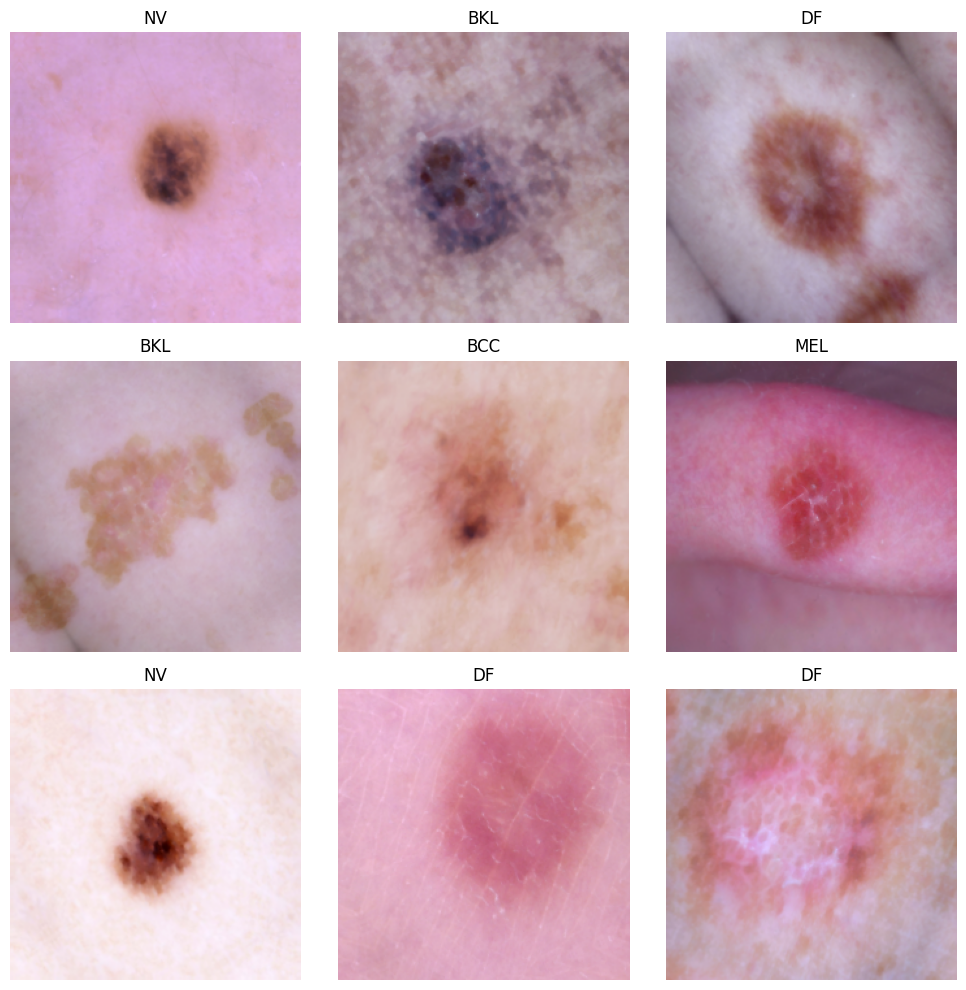

In [15]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        image = tf.cast(tf.clip_by_value(images[i], 0, 255), tf.uint8)
        plt.imshow(image)
        plt.title(class_name[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
base_model = DenseNet169(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))

x = preprocess_input(inputs)
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.001)
)(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(len(classes))(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="densenet169_undersampling"
)

model.summary()

51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "densenet169_undersampling"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       213,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,856,903 (49.05 MB)

 Trainable params: 214,023 (836.03 KB)

 Non-trainable params: 12,642,880 (48.23 MB)

In [17]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=4,
    min_lr=1e-7,
    verbose=1
)

checkpoint = keras.callbacks.ModelCheckpoint(
    CHECKPOINT_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [early_stopping, reduce_lr, checkpoint]

In [18]:
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks
)

Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 690ms/step - accuracy: 0.1506 - loss: 2.4519
Epoch 1: val_loss improved from None to 2.20479, saving model to ../models/transfer_learning/best_densenet169_undersampling.keras

Epoch 1: finished saving model to ../models/transfer_learning/best_densenet169_undersampling.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 933ms/step - accuracy: 0.1536 - loss: 2.3991 - val_accuracy: 0.1959 - val_loss: 2.2048 - learning_rate: 1.0000e-04
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 728ms/step - accuracy: 0.1972 - loss: 2.2515
Epoch 2: val_loss improved from 2.20479 to 2.09819, saving model to ../models/transfer_learning/best_densenet169_undersampling.keras

Epoch 2: finished saving model to ../models/transfer_learning/best_densenet169_undersampling.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 17s 894ms/step - accuracy: 0.1901 - loss: 2.2475 - val_accuracy: 0.2165 - val_loss: 2.0982 - learning_rate: 1.0000e-04
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 748ms/step - accuracy: 0.1966 - 

In [19]:
RUN_FINE_TUNING = False
FINE_TUNE_LAYERS = 30
FINE_TUNE_EPOCHS = 20
FINE_TUNE_LR = 1e-5

if RUN_FINE_TUNING:
    base_model.trainable = True

    for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"]
    )

    fine_tune_history = model.fit(
        train_ds,
        epochs=FINE_TUNE_EPOCHS,
        validation_data=val_ds,
        callbacks=callbacks
    )

    for key in fine_tune_history.history:
        history.history[key] = history.history.get(key, []) + fine_tune_history.history[key]

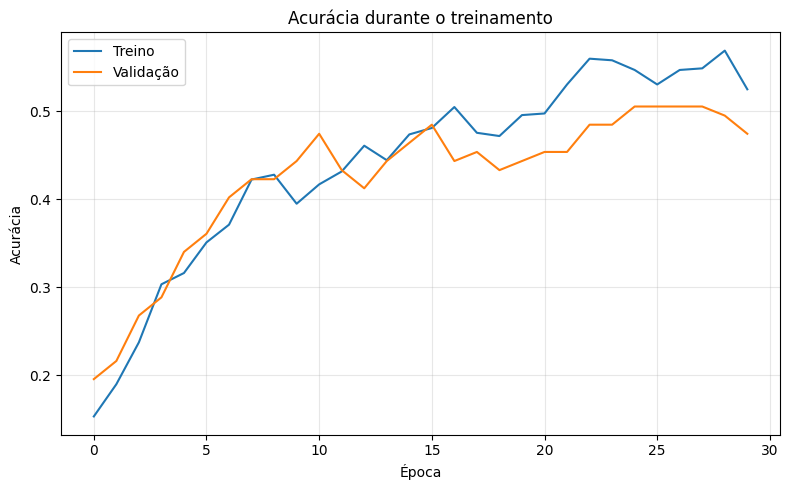

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Treino")
plt.plot(history.history["val_accuracy"], label="Validação")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.title("Acurácia durante o treinamento")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("densenet169_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

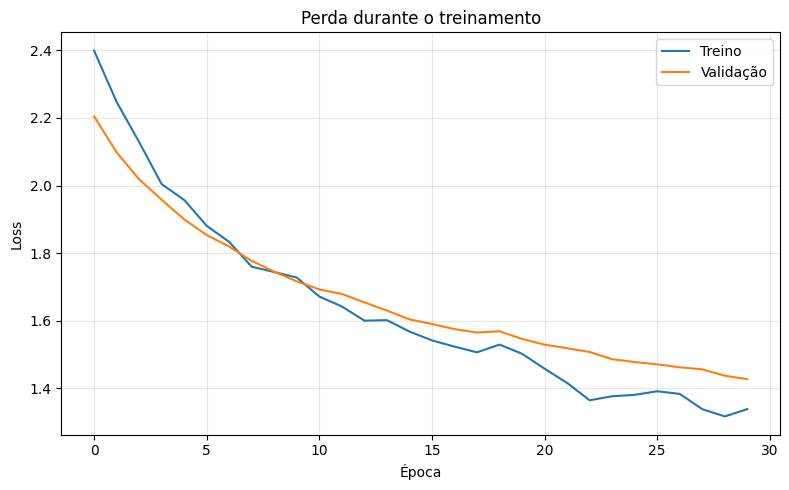

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Treino")
plt.plot(history.history["val_loss"], label="Validação")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Perda durante o treinamento")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("densenet169_loss.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
best_model = keras.models.load_model(CHECKPOINT_PATH)
best_model.summary()

Model: "densenet169_undersampling"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       213,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,284,951 (50.68 MB)

 Trainable params: 214,023 (836.03 KB)

 Non-trainable params: 12,642,880 (48.23 MB)

 Optimizer params: 428,048 (1.63 MB)

In [23]:
y_true = []
y_pred = []

for images, labels in test_ds:
    logits = best_model.predict(images, verbose=0)
    predictions = np.argmax(logits, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Relatório de Classificação:")
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

Relatório de Classificação:
              precision    recall  f1-score   support

         MEL     0.2788    0.4888    0.3550       223
          NV     0.9136    0.6704    0.7733      1341
         BCC     0.4224    0.4757    0.4475       103
       AKIEC     0.3108    0.3538    0.3309        65
         BKL     0.4196    0.2136    0.2831       220
          DF     0.0922    0.8261    0.1659        23
        VASC     0.2083    0.8929    0.3378        28

    accuracy                         0.5846      2003
   macro avg     0.3780    0.5602    0.3848      2003
weighted avg     0.7246    0.5846    0.6287      2003



In [24]:
accuracy = accuracy_score(y_true, y_pred)

precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

precision_weighted = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall_weighted = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("MÉTRICAS GERAIS DO MODELO")
print(f"Accuracy: {accuracy:.4f}")

print("\nMacro Average:")
print(f"  Precision: {precision_macro:.4f}")
print(f"  Recall: {recall_macro:.4f}")
print(f"  F1-Score: {f1_macro:.4f}")

print("\nWeighted Average:")
print(f"  Precision: {precision_weighted:.4f}")
print(f"  Recall: {recall_weighted:.4f}")
print(f"  F1-Score: {f1_weighted:.4f}")


MÉTRICAS GERAIS DO MODELO
Accuracy: 0.5846

Macro Average:
  Precision: 0.3780
  Recall: 0.5602
  F1-Score: 0.3848

Weighted Average:
  Precision: 0.7246
  Recall: 0.5846
  F1-Score: 0.6287


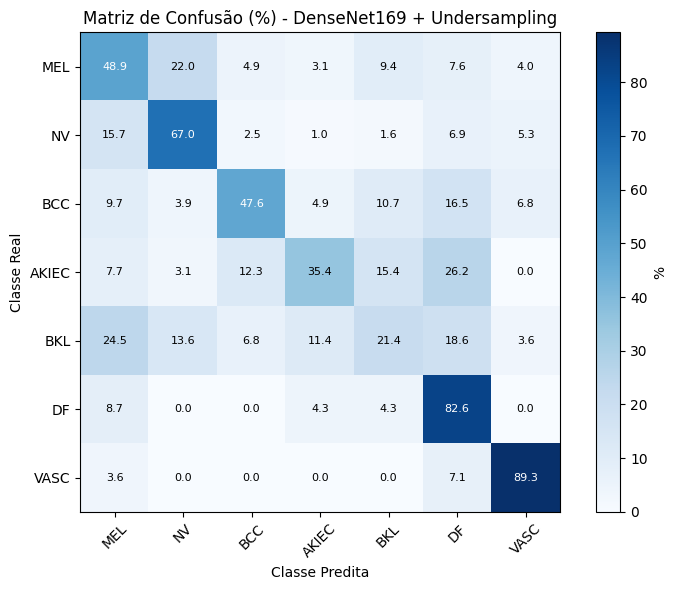

In [25]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))

cm_percent = cm.astype("float32") / cm.sum(axis=1, keepdims=True) * 100
cm_percent = np.nan_to_num(cm_percent)

plt.figure(figsize=(8, 6))
plt.imshow(cm_percent, interpolation="nearest", cmap="Blues")
plt.title("Matriz de Confusão (%) - DenseNet169 + Undersampling")
plt.colorbar(label="%")

tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

threshold = cm_percent.max() / 2

for i in range(cm_percent.shape[0]):
    for j in range(cm_percent.shape[1]):
        plt.text(
            j,
            i,
            f"{cm_percent[i, j]:.1f}",
            ha="center",
            va="center",
            color="white" if cm_percent[i, j] > threshold else "black",
            fontsize=8
        )

plt.ylabel("Classe Real")
plt.xlabel("Classe Predita")
plt.tight_layout()
plt.savefig("matriz_confusao_percentual_densenet169.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
test_examples = test_df.reset_index(drop=True).copy()
test_examples["y_true"] = y_true
test_examples["y_pred"] = y_pred
test_examples["correct"] = test_examples["y_true"] == test_examples["y_pred"]

correct_samples = test_examples[test_examples["correct"]].sample(
    min(4, test_examples["correct"].sum()),
    random_state=SEED
)

incorrect_samples = test_examples[~test_examples["correct"]].sample(
    min(4, (~test_examples["correct"]).sum()),
    random_state=SEED
)

samples_to_plot = pd.concat([correct_samples, incorrect_samples]).reset_index(drop=True)

plt.figure(figsize=(12, 6))

for i, row in samples_to_plot.iterrows():
    image = load_image_with_optional_dull_razor(row["image_path"])
    image = np.clip(image, 0, 255).astype("uint8")

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)

    true_label = class_name[int(row["y_true"])]
    pred_label = class_name[int(row["y_pred"])]

    plt.title(f"{true_label} → {pred_label}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.savefig("exemplos_classificacao_densenet169.png", dpi=300, bbox_inches="tight")
plt.show()

AttributeError: 'str' object has no attribute 'decode'

<Figure size 1200x600 with 0 Axes>

In [ ]:
best_model.save(FINAL_MODEL_PATH)

print(f"Modelo salvo em: {FINAL_MODEL_PATH}")
print(f"Melhor checkpoint salvo em: {CHECKPOINT_PATH}")

In [ ]:
best_epoch = int(np.argmin(history.history["val_loss"]))
print("Diagnóstico final pela melhor época:")
print(f"Melhor época: {best_epoch + 1}")
print(f"Train accuracy: {history.history['accuracy'][best_epoch]:.4f}")
print(f"Val accuracy: {history.history['val_accuracy'][best_epoch]:.4f}")
print(f"Train loss: {history.history['loss'][best_epoch]:.4f}")
print(f"Val loss: {history.history['val_loss'][best_epoch]:.4f}")